# Analytical solutions for quantum radiation reaction in high-intensity lasers

Original authors of the paper: T G Blackburn

Link to peer-reviewed paper: https://journals.aps.org/pra/abstract/10.1103/PhysRevA.109.022234

Link to pre-print: https://arxiv.org/abs/2312.03592

Author of this notebook: Óscar Amaro (2023, 2026)

Data from preprint retrieved with WebPlotDigitizer

Outline:
- [Figure 1](#Figure1): average electron energy as function of $a_0$ - PW
- [Figure 2](#Figure2): electron energy spread as function of $a_0$ - PW
- [Figure 3](#Figure3): ratio of the final and initial standard deviations - PW
- [Figure 4](#Figure4): electron energy spread as function of electron beam radius $R$ - Gaussian 3D

In [2]:
import QScatter
from QScatter import *     # numpy/matplotlib helpers and get_PW_sigF (Vranic et al. 2016, Eq. 17)
from scipy.special import erf
import warnings; warnings.filterwarnings('ignore', category=SyntaxWarning)

In [3]:
from numpy import sqrt, pi, log, exp
from scipy.constants import alpha
ME_MEV = 0.51099895          # electron rest energy [MeV]
A_S_08 = 329719.             # m/(hbar w0) at lambda = 0.8 um, so chi = 2 a0 gamma / A_S

def collision_params(E0_MeV, a0, lbd_um=0.8, T_fs=30.):
    """chi0 = 2 a0 mu0 w0/m,  Rc = alpha a0 chi0,  tau = 1.85 (T/fs)/(lambda/um)  [paper Eq. (17)]."""
    aS = A_S_08 * lbd_um / 0.8
    g0 = E0_MeV / ME_MEV
    chi0 = 2. * a0 * g0 / aS
    Rc = alpha * a0 * chi0
    tau = 1.85 * T_fs / lbd_um
    return chi0, Rc, tau

# cycle-averaged powers of |f|
def f2(phi, tau):  # <|f|^2> = (1/2) exp(-4 ln2 phi^2/tau^2)
    return 0.5 * exp(-4. * log(2) * phi**2 / tau**2)

def f3(phi, tau):  # <|f|^3> = (4/3pi) exp(-6 ln2 phi^2/tau^2)
    return 4. / (3. * pi) * exp(-6. * log(2) * phi**2 / tau**2)

def I_phi(phi, tau):
    """I(phi) = int_{-inf}^{phi} |f|^2 dpsi = (tau/8) sqrt(pi/ln2) [1 + erf(2 sqrt(ln2) phi/tau)]  (after Eq. 11)."""
    return tau / 8. * sqrt(pi / log(2)) * (1. + erf(2. * sqrt(log(2)) * phi / tau))

def J_phi(phi, tau):
    """int_{-inf}^{phi} <|f|^3> dpsi (closed form)."""
    return 4. / (3. * pi) * tau / 2. * sqrt(pi / (6. * log(2))) * (1. + erf(sqrt(6. * log(2)) * phi / tau))

def mu_hat_eq11(E0_MeV, a0, phi=np.inf, quantum=True, lbd_um=0.8, T_fs=30.):
    """Normalised mean energy, Eq. (11). quantum=False -> classical (first) term only."""
    chi0, Rc, tau = collision_params(E0_MeV, a0, lbd_um, T_fs)
    phi_e = min(phi, 6. * tau)                     # pulse is negligible beyond 6 tau
    D = 1. + 2. / 3. * Rc * I_phi(phi_e, tau)
    res = 1. / D
    if quantum:
        integ = quad(lambda p: Rc * f3(p, tau) / (1. + 2. / 3. * Rc * I_phi(p, tau)),
                     -6. * tau, phi_e, limit=200)[0]
        res += 55. * chi0 / (8. * sqrt(3.) * D**2) * integ
    return res

def sig2_hat_eq14(E0_MeV, a0, sig0_hat, phi=np.inf, adhoc=False, quantum=True, lbd_um=0.8, T_fs=30.):
    """Normalised variance, Eq. (14) (quantum) or Eq. (13) (quantum=False).
    adhoc=True applies the a0 -> a0/sqrt(2) correction of Sec. IV."""
    a = a0 / sqrt(2.) if adhoc else a0
    chi0, Rc, tau = collision_params(E0_MeV, a, lbd_um, T_fs)
    phi_e = min(phi, 6. * tau)
    D = 1. + 2. / 3. * Rc * I_phi(phi_e, tau)
    num = sig0_hat**2
    if quantum:
        num += 55. * Rc * chi0 / (24. * sqrt(3.)) * J_phi(phi_e, tau)
    return num / D**4

# --- fitted closed forms, Eqs. (15)-(16) (final values) ---
def mu_hat_eq15(E0_MeV, a0, quantum=True, lbd_um=0.8, T_fs=30.):
    chi0, Rc, tau = collision_params(E0_MeV, a0, lbd_um, T_fs)
    x = Rc * tau
    if not quantum:
        return 1. / (1. + 0.355 * x)
    F = 0.369 * x / (1. + 0.171 * x**0.6 + 0.0819 * x)
    return 1. / (1. + 0.355 * x) * (1. + 3.969 * chi0 * F / (1. + 0.355 * x))

def sig2_hat_eq16(E0_MeV, a0, sig0_hat, quantum=True, lbd_um=0.8, T_fs=30.):
    chi0, Rc, tau = collision_params(E0_MeV, a0, lbd_um, T_fs)
    x = Rc * tau
    if not quantum:
        return sig0_hat**2 / (1. + 0.355 * x)**4
    return (sig0_hat**2 + 0.173 * chi0 * x) / (1. + 0.178 * x)**4

# --- 3D (finite beam size) averaging, Eqs. (20)-(22) ---
def beam_moments_3D(E0_MeV, a0, R_um, w0_um, sig0_hat, quantum=True, lbd_um=0.8, T_fs=30.):
    """Returns (mu_hat_b, sig_hat_b). dNe/da = Ne k a^(k-1)/a0^k with k = w0^2/R^2 (Eq. 22).
    Substituting a = a0 s^(1/k) makes the weight uniform in s in [0,1]."""
    mu = lambda a: mu_hat_eq15(E0_MeV, a, quantum, lbd_um, T_fs)
    s2 = lambda a: sig2_hat_eq16(E0_MeV, a, sig0_hat, quantum, lbd_um, T_fs)
    if R_um == 0:
        return mu(a0), sqrt(s2(a0))
    k = w0_um**2 / R_um**2
    A = lambda s: a0 * s**(1. / k)
    m1 = quad(lambda s: mu(A(s)), 0, 1, limit=200)[0]
    m2 = quad(lambda s: mu(A(s))**2 + s2(A(s)), 0, 1, limit=200)[0]
    return m1, sqrt(m2 - m1**2)

def sig0_from_fwhm(frac):
    """sigma0/mu0 for a Gaussian with FWHM = frac * mu0."""
    return frac / (2. * sqrt(2. * log(2.)))

def wpd(fig, name):
    """Digitised dataset `name` of dataWPD/<fig>, sorted in x."""
    d = json.load(open('dataWPD/%s/wpd.json' % fig))
    for ds in d['datasetColl']:
        if ds['name'] == name:
            return np.array(sorted(p['value'] for p in ds['data']))
    raise KeyError(name)

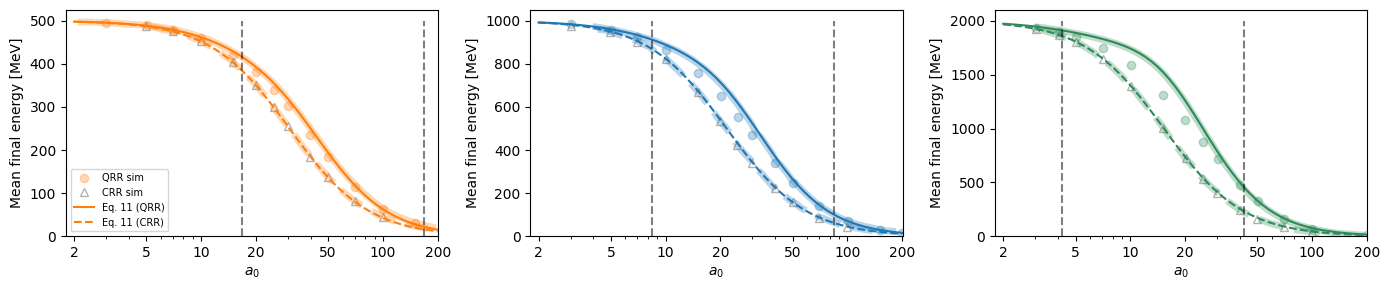

In [4]:
# thin lines / small markers: this notebook;  thick translucent lines / large markers: WPD data from paper
# vertical dashed lines: chi0 = 0.1 and 1.0
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14,3))
alphaPaper = 0.3
a0lst = np.logspace(np.log10(2), np.log10(200), 60)
E0lst = np.array([500, 1000, 2000]); cols = ['tab:orange', 'tab:blue', 'seagreen']
for i, (E0, col) in enumerate(zip(E0lst, cols)):
    fig_ = 'fig1' + 'abc'[i]
    v = wpd(fig_, 'Dots');   axes[i].plot(v[:,0], v[:,1], 'o', color=col, alpha=alphaPaper, label='QRR sim')
    v = wpd(fig_, 'Triang'); axes[i].plot(v[:,0], v[:,1], 'w^', markeredgecolor='black', alpha=alphaPaper, label='CRR sim')
    v = wpd(fig_, 'Line');   axes[i].plot(v[:,0], v[:,1], '-', color=col, alpha=alphaPaper, linewidth=5)
    v = wpd(fig_, 'Dashed'); axes[i].plot(v[:,0], v[:,1], '--', color=col, alpha=alphaPaper, linewidth=5)
    axes[i].plot(a0lst, [E0*mu_hat_eq11(E0, a) for a in a0lst], '-', color=col, label='Eq. 11 (QRR)')
    axes[i].plot(a0lst, [E0*mu_hat_eq11(E0, a, quantum=False) for a in a0lst], '--', color=col, label='Eq. 11 (CRR)')

def a0vert(E0, chi): return chi/(2*E0/0.511/329719)  # 0.8 um laser
x = np.linspace(0, 1)
for i in range(3):
    axes[i].plot(x*0+a0vert(E0lst[i],0.1), x*E0lst[i], 'k--', alpha=0.5)
    axes[i].plot(x*0+a0vert(E0lst[i],1),   x*E0lst[i], 'k--', alpha=0.5)
    axes[i].set_xscale('log'); axes[i].set_xlabel(r'$a_0$'); axes[i].set_ylabel(r'Mean final energy [MeV]')
    axes[i].set_xlim([1.8,201]); axes[i].set_xticks([2,5,10,20,50,100,200]); axes[i].set_ylim([0, 1.05*E0lst[i]])
    axes[i].get_xaxis().set_major_formatter(mticker.ScalarFormatter())
axes[0].legend(loc='lower left', fontsize=7)
plt.tight_layout()
#plt.savefig('fig1.pdf', transparent=True)
plt.show()

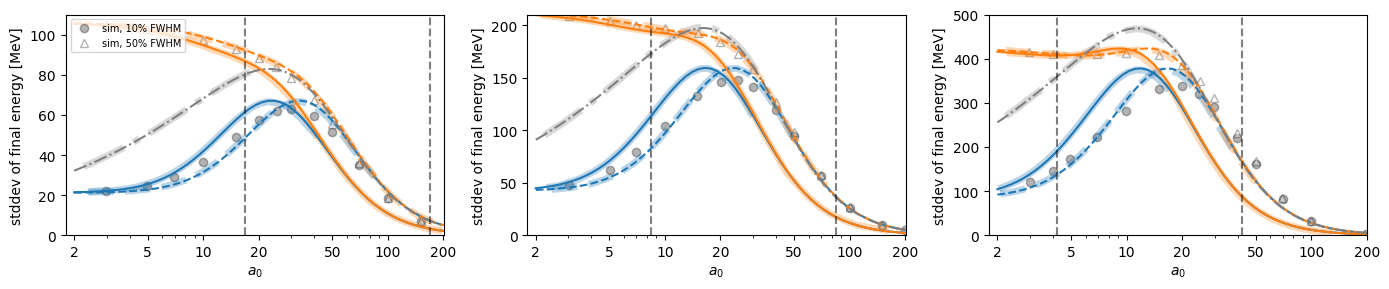

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14,3))
alphaPaper = 0.3
a0lst = np.logspace(np.log10(2), np.log10(200), 60)
E0lst = np.array([500, 1000, 2000]); maxY = np.array([110, 210, 500])
for i, E0 in enumerate(E0lst):
    fig_ = 'fig2' + 'abc'[i]
    v = wpd(fig_, 'Vranic2016'); axes[i].plot(v[:,0], v[:,1], '-.', color='grey', alpha=alphaPaper, linewidth=5)
    v = wpd(fig_, 'Dots');   axes[i].plot(v[:,0], v[:,1], 'ko', alpha=alphaPaper, label='sim, 10% FWHM')
    v = wpd(fig_, 'Triang'); axes[i].plot(v[:,0], v[:,1], 'w^', markeredgecolor='black', alpha=alphaPaper, label='sim, 50% FWHM')
    for nm, ls, col in [('LineBlue','-','tab:blue'), ('LineOrange','-','tab:orange'), ('DashBlue','--','tab:blue'), ('DashOrange','--','tab:orange')]:
        v = wpd(fig_, nm); axes[i].plot(v[:,0], v[:,1], ls, color=col, alpha=alphaPaper, linewidth=5)
    for frac, col in [(0.1, 'tab:blue'), (0.5, 'tab:orange')]:
        s0 = sig0_from_fwhm(frac)
        axes[i].plot(a0lst, [E0*np.sqrt(sig2_hat_eq14(E0, a, s0)) for a in a0lst], '-', color=col)
        axes[i].plot(a0lst, [E0*np.sqrt(sig2_hat_eq14(E0, a, s0, adhoc=True)) for a in a0lst], '--', color=col)
    # Vranic et al. NJP 18, 073035 (2016), Eq. 17 (tau in fs)
    axes[i].plot(a0lst, get_PW_sigF(E0/0.511, a0lst, 0.8, 30)*0.511, '-.', color='grey')

x = np.linspace(0, 1)
for i in range(3):
    axes[i].plot(x*0+a0vert(E0lst[i],0.1), x*maxY[i], 'k--', alpha=0.5)
    axes[i].plot(x*0+a0vert(E0lst[i],1),   x*maxY[i], 'k--', alpha=0.5)
    axes[i].set_xscale('log'); axes[i].set_xlabel(r'$a_0$'); axes[i].set_ylabel(r'stddev of final energy [MeV]')
    axes[i].set_xlim([1.8,201]); axes[i].set_xticks([2,5,10,20,50,100,200]); axes[i].set_ylim([0, maxY[i]])
    axes[i].get_xaxis().set_major_formatter(mticker.ScalarFormatter())
axes[0].legend(loc='upper left', fontsize=7)
plt.tight_layout()
#plt.savefig('fig2.pdf', transparent=True)
plt.show()

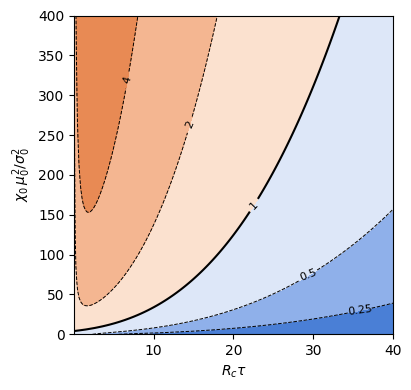

In [6]:
# sigma_f/sigma_0 from Eq. 16:  (sigma_f/sigma_0)^2 = (1 + 0.173 X Rc tau)/(1 + 0.178 Rc tau)^4,  X = chi0 mu0^2/sigma0^2
xdim = 200
x = np.linspace(0.05, 40, xdim)   # start just above 0: sigma_f/sigma_0 = 1 identically at Rc tau = 0
y = np.linspace(0, 400, xdim)
RcT, X0 = np.meshgrid(x, y)
Z = np.sqrt((1 + 0.173*X0*RcT)/(1 + 0.178*RcT)**4)

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
cplevels = [1e-3, 0.25, 0.5, 1, 2, 4, 1e2]
cp = axes.contourf(RcT, X0, Z, levels=cplevels, colors=['#4a7fd6','#8fb0ea','#dde7f8','#fbe1cf','#f4b691','#e88a54'])
cl = axes.contour(RcT, X0, Z, levels=[0.25, 0.5, 1, 2, 4], colors='k', linewidths=[0.7,0.7,1.5,0.7,0.7],
                  linestyles=['--','--','-','--','--'])
axes.clabel(cl, fmt='%g', fontsize=8, manual=[(4,330),(12,280),(22,170),(30,50),(36,12)])
axes.set_xlabel(r'$R_c \tau$')
axes.set_ylabel(r'$\chi_0\,\mu_0^2/\sigma_0^2$')
axes.set_box_aspect(1)
plt.tight_layout()
#plt.savefig('fig3.pdf', transparent=True)
plt.show()

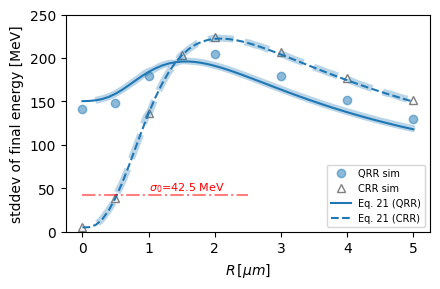

In [7]:
# Eq. 21 with dNe/da = Ne k a^(k-1) / a0^k.  k = w0^2/(2 R^2) for rms beam size R (reproduces the paper's curves);
# Eq. 22 as printed has k = w0^2/R^2 -> set RMS_CONVENTION = False to use it literally.
RMS_CONVENTION = True
E0, a0, w0 = 1000, 30, 2.5
s0 = sig0_from_fwhm(0.1)                                    # 42.5 MeV
Rlst = np.linspace(0, 5, 51)
Reff = Rlst*np.sqrt(2) if RMS_CONVENTION else Rlst          # beam_moments_3D uses k = w0^2/Reff^2
sq = [E0*beam_moments_3D(E0, a0, R, w0, s0)[1] for R in Reff]
sc = [E0*beam_moments_3D(E0, a0, R, w0, s0, quantum=False)[1] for R in Reff]

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4.5,3))
alphaPaper = 0.5
v = wpd('fig4', 'Dots');  plt.plot(v[:,0], v[:,1], 'o', color='tab:blue', alpha=alphaPaper, label='QRR sim')
v = wpd('fig4', 'Trian'); plt.plot(v[:,0], v[:,1], 'w^', markersize=6, markeredgecolor='black', alpha=alphaPaper, label='CRR sim')
v = wpd('fig4', 'Line');  plt.plot(v[:,0], v[:,1], '-',  color='tab:blue', alpha=0.3, linewidth=5)
v = wpd('fig4', 'Dash');  plt.plot(v[:,0], v[:,1], '--', color='tab:blue', alpha=0.3, linewidth=5)
plt.plot(Rlst, sq, '-',  color='tab:blue', label='Eq. 21 (QRR)')
plt.plot(Rlst, sc, '--', color='tab:blue', label='Eq. 21 (CRR)')
plt.plot([0, 2.5], [E0*s0]*2, 'r-.', alpha=alphaPaper)
plt.text(1.0, E0*s0+5, r'$\sigma_0$=%.1f MeV' % (E0*s0), color='r', fontsize=8)
plt.xlabel(r'$R\,[\mu m]$'); plt.ylabel(r'stddev of final energy [MeV]')
plt.ylim([0, 250]); plt.legend(fontsize=7, loc='lower right')
plt.tight_layout()
#plt.savefig('fig4.pdf', transparent=True)
plt.show()